**BG/NBD** 模型通常使用 lifetimes 库来实现，它封装了复杂的概率推导；
而 **Gamma**分布通常作为其先验分布或独立统计工具，使用 scipy.stats.gamma 处理。

一些关键的值：
 * recency: 最近一次购买距观察结束的天数
 * T: 客户总生命周期天数
 * frequency: 观察期内的购买次数



❗️哪些场景不适用？？

 1. **非重复购买场景**：取决于你的行业，如果是一次性消费，或者是一次性礼品赠送，NBD 系列完全失效。
 2. **时间间隔极短或极长**​：NBD 假设购买过程是一个泊松过程。如果客户购买具有极强的周期性（如每月固定领优惠券才买），NBD 会低估这种规律性。此时应考虑 Markov Chains（马尔可夫链） 或 CVRM​。
3. **促销驱动型**​：如果购买行为主要由外部促销触发，而非内在需求，NBD 的参数（α 和 β）会变得不稳定，无法反映真实的客户终身价值。

# data：




数据集地址：https://archive.ics.uci.edu/dataset/352/online+retail

该数据集中包含2010年12月1日至2011年12月9日期间发生的所有在英国和注册的非商店在线零售业务的交易。该公司主要销售独特的全场礼品。该公司的许多客户都是批发商。


字段描述：

InvoiceNo：发票编号.如果此代码以字母’c’开头，则表示取消

StockCode：产品代码

Description：产品名称

Quantity：每笔交易的每件产品的数量

InvoiceDate：Invice日期

UnitPrice：单价

CustomerID：客户编号

Country：国家名称


In [1]:
! pip install ucimlrepo
# https://archive.ics.uci.edu/dataset/352/online+retail
from ucimlrepo import fetch_ucirepo

# fetch dataset
online_retail = fetch_ucirepo(id=352)

# data (as pandas dataframes)
X = online_retail.data.features
y = online_retail.data.targets

# metadata
print(online_retail.metadata)

# variable information
print(online_retail.variables)


{'uci_id': 352, 'name': 'Online Retail', 'repository_url': 'https://archive.ics.uci.edu/dataset/352/online+retail', 'data_url': 'https://archive.ics.uci.edu/static/public/352/data.csv', 'abstract': 'This is a transactional data set which contains all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate', 'Sequential', 'Time-Series'], 'num_instances': 541909, 'num_features': 6, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': None, 'index_col': ['InvoiceNo', 'StockCode'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2015, 'last_updated': 'Mon Oct 21 2024', 'dataset_doi': '10.24432/C5BW33', 'creators': ['Daqing Chen'], 'intro_paper': {'ID': 361, 'type': 'NATIVE', 'title': 'Data mining for the online retail industry: A case study of RFM model-based customer segmenta

In [26]:
! pip install lifetimes
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('ggplot')
from lifetimes.plotting import *
from lifetimes.utils import *
from lifetimes import *

warnings.filterwarnings('ignore')

# 读取数据
# df = online_retail.data.features
df = online_retail.data.original
df = df.copy()
df.head(2).T


,0,1
InvoiceNo,536365,536365
StockCode,85123A,71053
Description,WHITE HANGING HEART T-LIGHT HOLDER,WHITE METAL LANTERN
Quantity,6,6
InvoiceDate,12/1/2010 8:26,12/1/2010 8:26
UnitPrice,2.55,3.39
CustomerID,17850.0,17850.0
Country,United Kingdom,United Kingdom


In [27]:
df.describe()


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [37]:
# 查看以‘C’开头的是否都是数量为负
(df[df.InvoiceNo.map(lambda x:str(x)[0] == 'C')].Quantity > 0).any()

np.False_

In [33]:
# 取消订单情况 取消单发票以‘C’开头，长度为7
df.InvoiceNo.map(lambda x:str(x)[0] == 'C').value_counts()



,count
InvoiceNo,
False,532621
True,9288


In [34]:
(df.Quantity < 0).value_counts()

,count
Quantity,
False,531285
True,10624


In [30]:
# 由上可见除了以“C”开头的数据，还有其他数量小于0的数据
df[df.InvoiceNo.map(lambda x:str(x)[0] != 'C')].query('Quantity < 0')


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,12/1/2010 16:50,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,12/2/2010 14:42,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,12/3/2010 15:30,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,12/3/2010 15:30,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,12/3/2010 15:30,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
535333,581210,23395,check,-26,12/7/2011 18:36,0.0,NaN,United Kingdom
535335,581212,22578,lost,-1050,12/7/2011 18:38,0.0,NaN,United Kingdom
535336,581213,22576,check,-30,12/7/2011 18:38,0.0,NaN,United Kingdom
536908,581226,23090,missing,-338,12/8/2011 9:56,0.0,NaN,United Kingdom


In [40]:
# ### 筛选出数量价格
# df.query('Quantity > 0 & UnitPrice >0', inplace=True)
# # 检查缺失值
# df.isna().sum()

# # 弃去缺失值
# df.dropna(inplace=True)

# ### 创建价格列（数量×单价）
# df['Sales'] = df.Quantity*df.UnitPrice


In [41]:

df = df[['InvoiceNo', 'CustomerID', 'InvoiceDate', 'Sales']]

### 更改用户ID类型
df.CustomerID = df.CustomerID.astype('object')

df.nunique()

,0
InvoiceNo,18532
CustomerID,4338
InvoiceDate,17282
Sales,2939


# CLV建模探索

In [42]:
data = summary_data_from_transaction_data(df, 'CustomerID', 'InvoiceDate',
                         monetary_value_col='Sales',
                         observation_period_end='2011-12-9')
data.sort_values('monetary_value').head()


,frequency,recency,T,monetary_value
CustomerID,,,,
17458.0,0.0,0.0,15.0,0.0
15634.0,0.0,0.0,17.0,0.0
15623.0,0.0,0.0,141.0,0.0
15619.0,0.0,0.0,10.0,0.0
16812.0,0.0,0.0,360.0,0.0


<Axes: ylabel='Frequency'>

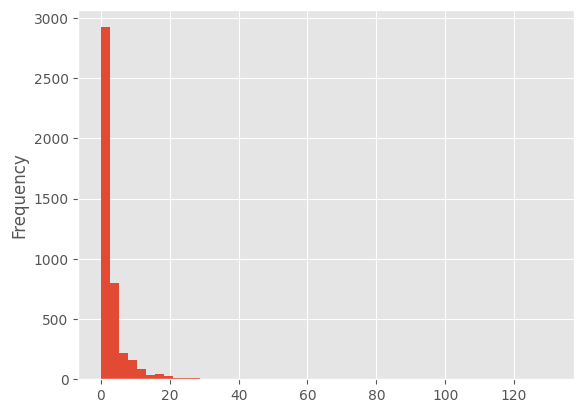

In [43]:
data['frequency'].plot(kind='hist', bins=50) # 频率分布直方图


<Axes: xlabel='frequency'>

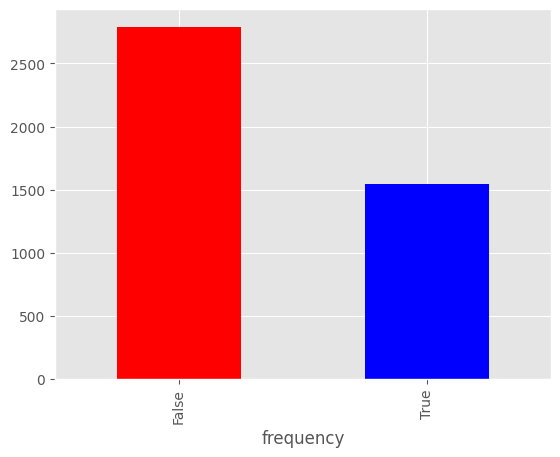

In [50]:
# 说在周期内只消费过一次比例
(data.frequency == 0).value_counts().plot.bar(color=['red', 'blue'])


In [49]:
print(f'频率为0占总体 {round(sum(data['frequency'] == 0)/float(len(data)),2)} ')


频率为0占总体 0.36 


In [51]:

# 使用BG / NBD模型进行频率分析
from lifetimes import BetaGeoFitter
bgf = BetaGeoFitter(penalizer_coef=0.0)
bgf.fit(data['frequency'], data['recency'], data['T'])
print(bgf)
# 0.83/68.91 * 30 = 0.36 次/月==> 客户平均每 2.7 个月回购一次东西


<lifetimes.BetaGeoFitter: fitted with 4338 subjects, a: 0.00, alpha: 68.91, b: 6.75, r: 0.83>


# 可视化

<Axes: title={'center': 'Expected Number of Future Purchases for 1 Unit of Time,\nby Frequency and Recency of a Customer'}, xlabel="Customer's Historical Frequency", ylabel="Customer's Recency">

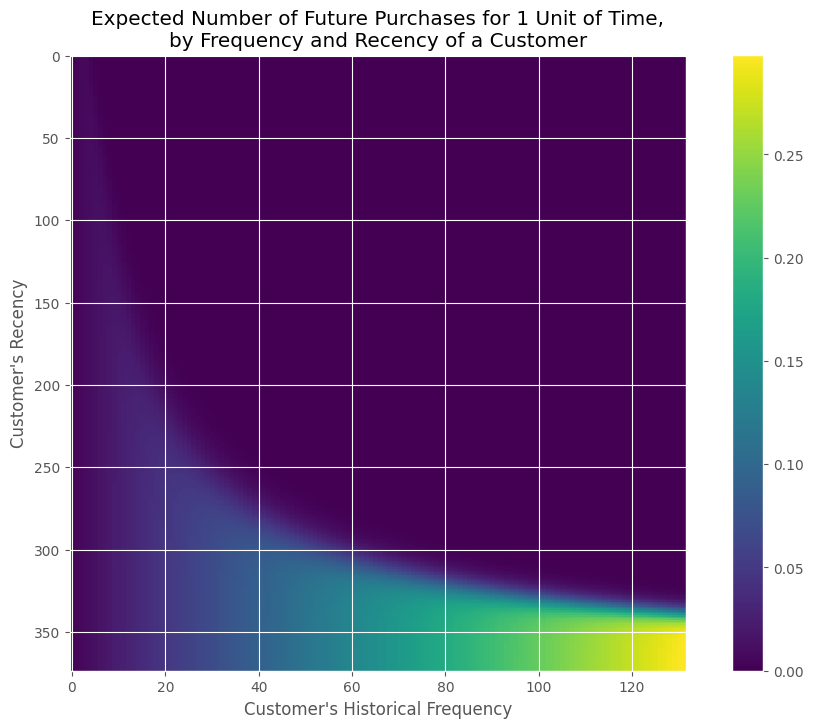

In [52]:
from lifetimes.plotting import plot_frequency_recency_matrix
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(12,8))
plot_frequency_recency_matrix(bgf)
# 横轴是 Frequency - 消费频次，越往右，代表客户过去在你这里买东西的次数越多。
# 纵轴Recency - 第一次购买和最后一次购买之间的时间差，0从左上角开始，越往下，代表客户是一个“老客户”。

# 预测哪些客户还在

<Axes: title={'center': 'Probability Customer is Alive,\nby Frequency and Recency of a Customer'}, xlabel="Customer's Historical Frequency", ylabel="Customer's Recency">

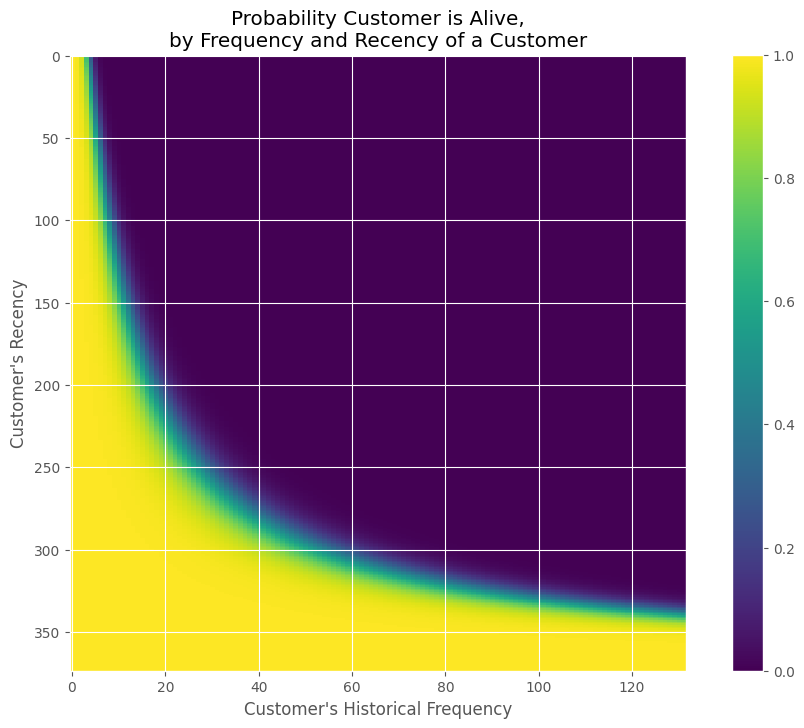

In [53]:
from lifetimes.plotting import plot_probability_alive_matrix
fig = plt.figure(figsize=(12,8))
plot_probability_alive_matrix(bgf)


# gamma-gamma模型估算客户终生价值

BG/NBD模型只对客户存续时间和交易次数进行建模，并不涉及客户未来交易所带来的价值。

In [56]:
returning_customers_summary = data[data['frequency']>0]
returning_customers_summary.shape[0]
# 仅估算至少有一次重复购买的客户。因此，我们估计有2,790位客户

2790

In [55]:

# 模型训练
from lifetimes import GammaGammaFitter
ggf = GammaGammaFitter(penalizer_coef = 0)
ggf.fit(returning_customers_summary['frequency'],
        returning_customers_summary['monetary_value'])
#
# 这样我们可以估算每个客户的平均交易价值
ggf.conditional_expected_average_profit(
        data['frequency'],
        data['monetary_value']
    ).head()


,0
CustomerID,
12346.0,414.648236
12347.0,602.096753
12348.0,492.520540
12349.0,414.648236
12350.0,414.648236


BG/NBD， Gamma-Gamma模型不是万能：

如果你的数据中，有极大比例的客户（例如 >50%）在观察期内一次都没买​，标准的 NBD 模型会产生严重的偏差。
其他方案​：使用 Zero-Inflated BG/NBD 或 hurdle models障碍模型​。


引入协变量（Covariates）
标准 NBD 假设所有客户的购买频率 λ 和流失率 μ 仅由随机效应决定，忽略了客户属性（如年龄、渠道来源、是否会员等级）。
方案​：如果业务需要精细化运营，应转向 Logistic Regression-based CLV 或 Machine Learning 模型（如 XGBoost + Survival Analysis）​，将客户画像作为特征输入。


产品生命周期阶段
对于新品上市初期，数据稀疏，NBD 的参数估计方差极大，不可信。

方案​：采用 相似品类映射法​，借用成熟品类的参数先验分布。
